# Clothing Category Recognition - Phase 2 master notebook

**Nakul, Sudeshhna, Puneet, Samarth and Neelanshu, Section A.**

The completed Phase 2 comparison examines a small CNN, the Phase 1 HOG + SVM
reference, and HOG/CNN-feature fusion with matched Logistic Regression controls.
This notebook reads saved predictions, checks their original IDs and labels,
and derives the main reported scores from integer confusion counts.

Install the repository with `python -m pip install -e '.[dev,phase2]'` and use its
Python environment as the notebook kernel. Downloaded official IDX files are
checksum verified. Read the results with the shared methodology in
`docs/phase2_training_protocol.md` and `docs/phase2_integration_nakul.md`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from clothing_ml.data import CLASS_NAMES, load_official
from clothing_ml.utils import ROOT, read_json, sha256
from clothing_ml.phase2 import reporting as review

plt.rcParams.update({"font.size": 10, "figure.figsize": (10, 4),
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 62)
evidence = review.reviewed_evidence()
comparison = evidence["comparison"]
cnn = comparison.set_index("row").loc["selected_cnn"]
svm = comparison.set_index("row").loc["hog_svm"]
print("Prediction files independently checked:", evidence["audit_count"])
print("Saved split SHA-256:", evidence["freeze"]["split_sha256"])

Prediction files independently checked: 31
Saved split SHA-256: 9172928b23246a9a23877f6ad6428698b97ea5de6ef13e6b1b9cafec24380ec9


## tl;dr

In [2]:
display(Markdown(
    f"The validation-selected **CNN-3** achieved **{cnn.test_accuracy:.2%} official-test accuracy** "
    f"and **{cnn.test_macro_f1:.4f} macro F1**, compared with **{svm.test_accuracy:.2%}** and "
    f"**{svm.test_macro_f1:.4f}** for HOG + SVM. The accuracy gain is "
    f"**{100*(cnn.test_accuracy-svm.test_accuracy):+.2f} percentage points**. "
    f"**Shirt recall fell from {svm.shirt_recall:.1%} to {cnn.shirt_recall:.1%}.** "
    "Fusion scored below embedding-only LR on validation. "
    f"Recorded same-machine CPU batch cost was **{cnn.ms_per_image:.3f} ms/image** for the CNN "
    f"and **{svm.ms_per_image:.3f} ms/image** for HOG + SVM."))

The validation-selected **CNN-3** achieved **92.14% official-test accuracy** and **0.9207 macro F1**, compared with **90.91%** and **0.9090** for HOG + SVM. The accuracy gain is **+1.23 percentage points**. **Shirt recall fell from 73.3% to 71.7%.** Fusion scored below embedding-only LR on validation. Recorded same-machine CPU batch cost was **0.312 ms/image** for the CNN and **19.748 ms/image** for HOG + SVM.

## Context & Methods

Four seed-42 configurations trained on identical 48,000 fit IDs. Validation on
12,000 original training images selected the CNN by macro F1, then accuracy,
then declared run order. Each run kept its highest validation-F1 checkpoint.
AdamW used LR 0.001 and weight decay 0.0001. Cross-entropy accepted logits.
Batch size was 128, the epoch cap was 25, and patience was 5.

The selected CNN and three LR feature heads entered a hashed freeze before
Phase 2 official-test evaluation. Each LR head compared C=0.1 and 1 on the
same fit and validation IDs. The later 50%-translation run stayed a
validation-only ablation outside the frozen selection set.

### Key assumptions and limits

- The official test was already examined in Phase 1. These scores are a
  comparison on the same public benchmark. Phase 2 configurations used validation.
- One training seed and one split limit evidence about training variability.
- A paired bootstrap over test-ID pairs describes benchmark-sample variability.
- Original timing used one Apple M3 CPU and includes input conversion and features.
- The frozen encoder was supervised by fit labels and selected on validation.
  LR-head validation uses those same validation IDs, so it is a development
  comparison with selection reuse. The held-out test provides the final comparison.
- See `results/phase2/full/test_access_log.md` for the fixed-row test attempts and
  the artifact-loading repair. Source revisions and freeze history remain recorded.

## Data

### Original IDs and class balance

In [3]:
train_images, train_labels = load_official("train")
with np.load(ROOT / "data/full_indices.npz") as split:
    fit_ids, val_ids = split["train_idx"], split["val_idx"]
assert not np.intersect1d(fit_ids, val_ids).size
assert len(fit_ids) == 48000 and len(val_ids) == 12000
counts = pd.DataFrame({"Category": CLASS_NAMES,
                      "Fit": np.bincount(train_labels[fit_ids], minlength=10),
                      "Validation": np.bincount(train_labels[val_ids], minlength=10)})
display(counts)
print("Official training shape:", train_images.shape, train_images.dtype)

,Category,Fit,Validation
0,T-shirt/top,4800,1200
1,Trouser,4800,1200
2,Pullover,4800,1200
3,Dress,4800,1200
4,Coat,4800,1200
5,Sandal,4800,1200
6,Shirt,4800,1200
7,Sneaker,4800,1200
8,Bag,4800,1200
9,Ankle boot,4800,1200


Official training shape: (60000, 28, 28) uint8


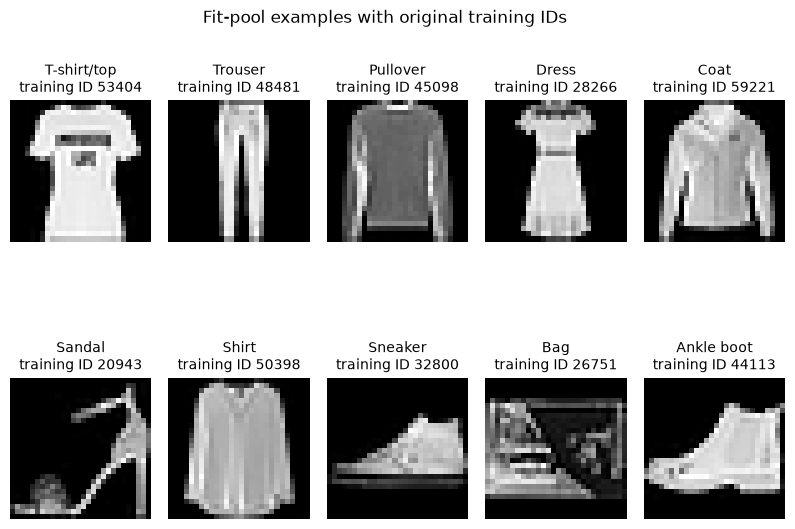

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5.5))
for label, axis in enumerate(axes.flat):
    sample_id = int(fit_ids[train_labels[fit_ids] == label][0])
    axis.imshow(train_images[sample_id], cmap="gray", vmin=0, vmax=255)
    axis.set_title(f"{CLASS_NAMES[label]}\ntraining ID {sample_id}", fontsize=10)
    axis.axis("off")
fig.suptitle("Fit-pool examples with original training IDs")
fig.subplots_adjust(hspace=.55, wspace=.12, top=.85, bottom=.02)
plt.show()

The recorded near-duplicate audit found five validation images and six official
test images within pixel RMS 5 of an image in the respective fit/training pool.
The headline results use the full official partitions. The pixel-distance audit
has limited coverage of semantically related garments under different views.

### CNN architecture

The **trained** three-block model uses channels **32, 64, 128**. Its third pool
reduces a 7x7 map to 3x3. The resulting smaller dense input yields **167,114**
trainable parameters. CNN-2 has **220,234**. The earlier work guide also proposed
a 64-channel third-block variant with 93,322 parameters. The results below refer
to the actual 128-channel model stored with the checkpoints.

In [5]:
record = evidence["cnn_records"][review.CNN_ID]
display(pd.DataFrame(record["shape_table"]))
print("CNN-3 parameter count:", record["parameters"])
print("Best epoch:", record["best_epoch"], "| Final epoch:", record["stop_epoch"])
print("Checkpoint SHA-256:", record["checkpoint_sha256"])

,layer,output_shape,parameters
0,0:Conv2d,"[32, 28, 28]",320
1,1:ReLU,"[32, 28, 28]",0
2,2:MaxPool2d,"[32, 14, 14]",0
3,3:Conv2d,"[64, 14, 14]",18496
4,4:ReLU,"[64, 14, 14]",0
5,5:MaxPool2d,"[64, 7, 7]",0
6,6:Conv2d,"[128, 7, 7]",73856
7,7:ReLU,"[128, 7, 7]",0
8,8:MaxPool2d,"[128, 3, 3]",0
9,dense:Sequential,[64],73792


CNN-3 parameter count: 167114
Best epoch: 22 | Final epoch: 25
Checkpoint SHA-256: e29a9d77d042c3e645e465ccb918c2f815467f8806adb0bbcf5474f563ce52e7


## Results

### Learning curves and checkpoint selection

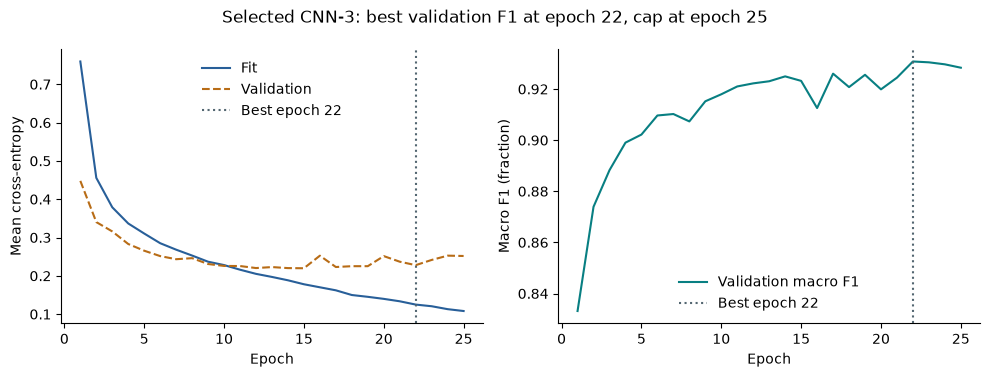

In [6]:
review.learning_plot(evidence)
plt.show()

Epoch 22 had the highest validation macro F1. Training continued to the cap at
25 and then reloaded that checkpoint. The loss-minimizing epoch differs because
checkpoint selection uses macro F1. The checkpoint reload reproduced every one
of the 12,000 saved validation predictions after the data-adapter integration.

### Controlled validation comparisons

,name,parameters,val_accuracy,val_macro_f1,shirt_recall,best_epoch,stop_epoch,selectable
3,cnn2,220234,0.9269,0.9267,0.7717,24,25,True
2,cnn2_p0,220234,0.9230,0.9231,0.8050,17,22,True
1,cnn2_aug,220234,0.9210,0.9202,0.6908,25,25,True
4,cnn3,167114,0.9309,0.9308,0.7908,22,25,True
0,cnn2_aug_p50,220234,0.9287,0.9279,0.7233,25,25,False


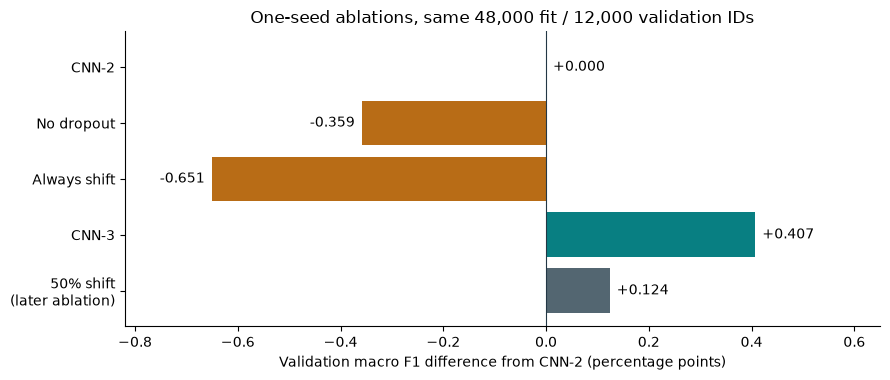

In [7]:
candidates = evidence["cnn_candidates"]
display(candidates[["name", "parameters", "val_accuracy", "val_macro_f1",
                    "shirt_recall", "best_epoch", "stop_epoch", "selectable"]])
review.ablation_plot(evidence)
plt.show()

Against CNN-2, removing dropout reduced validation F1 by 0.0036. Always shifting
reduced it by 0.0065. The three-block architecture increased it by 0.0041 while
also changing the final spatial map and dense-head size. The later 50%-shift
ablation increased F1 by 0.0012 but reduced Shirt recall by about 4.8 percentage
points. These are one-seed observations under a shared checkpoint rule.

### Frozen official-test comparison

,run_id,row,model,val_macro_f1,Test accuracy,Test macro F1,Shirt recall,CPU ms/image
0,full_hog_svm_3fd9d87a,hog_svm,HOG + SVM,0.9114,0.9091,0.9090,0.733,19.7483
1,full_cnn3_s42_80a2edee,selected_cnn,CNN-3,0.9308,0.9214,0.9207,0.717,0.3120
2,full_emb_lr_C0.1_033b7a83,emb_lr,Embedding + LR,0.9319,0.9221,0.9218,0.746,0.3146
3,full_hog_lr_C0.1_c1406307,hog_lr,HOG + LR,0.8832,0.8760,0.8757,0.661,0.2053
4,full_fusion_lr_C0.1_db46d180,fusion_lr,Fusion + LR,0.9261,0.9206,0.9206,0.760,0.5175


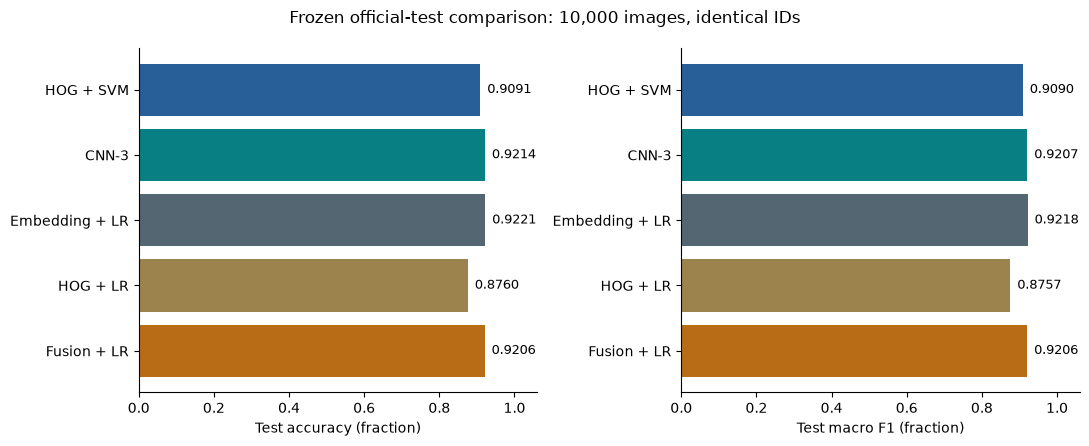

In [8]:
display(comparison.rename(columns={"test_accuracy": "Test accuracy", "test_macro_f1": "Test macro F1",
                                  "shirt_recall": "Shirt recall", "ms_per_image": "CPU ms/image"}))
review.comparison_plot(evidence)
plt.show()

CNN-3 reaches 92.14% accuracy and 0.9207 macro F1. The embedding-only LR control
scores 92.21% and 0.9218. It entered testing as a predeclared control and has the
highest aggregate score among these frozen Phase 2 rows. CNN-3 remains the
CNN selected by the original validation rule.

### Fusion and its single-feature controls

,row,C,feature_dim,val_macro_f1,converged
0,emb_lr,0.1,64,0.9319,True
1,emb_lr,1.0,64,0.9318,True
2,hog_lr,0.1,1296,0.8832,True
3,hog_lr,1.0,1296,0.8747,True
4,fusion_lr,0.1,1360,0.9261,True
5,fusion_lr,1.0,1360,0.9200,True


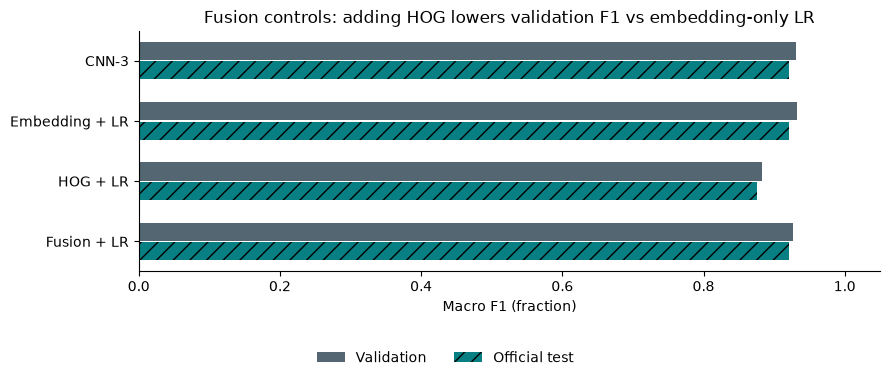

In [9]:
display(evidence["fusion_candidates"][["row", "C", "feature_dim", "val_macro_f1", "converged"]])
review.hybrid_plot(evidence)
plt.show()

Fusion joins 64 CNN embedding values with 1,296 HOG values and fits LR after
training-only standardization. Its validation macro F1 is 0.9261 versus 0.9319
for embedding-only LR. Official-test F1 is 0.9206 versus 0.9218. The controls
provide no support for an aggregate fusion improvement in this experiment.
Fusion's 76.0% test Shirt recall is an exploratory class trade-off.

### Category recall and paired mistakes

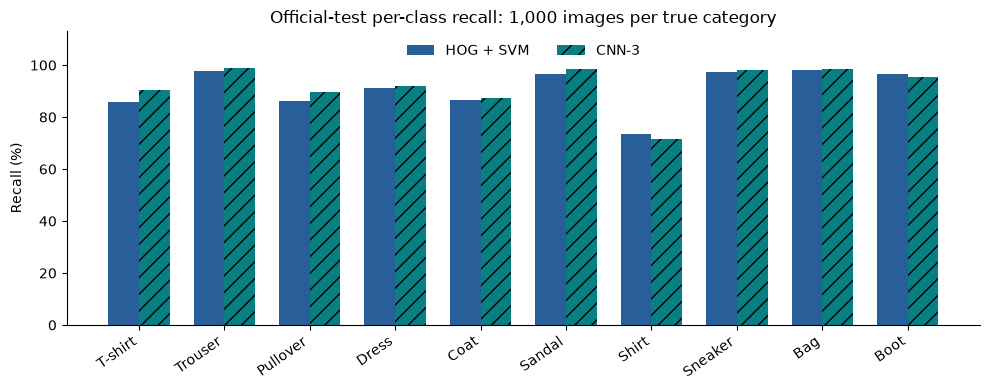

,run_id,precision,recall,f1,support
66,full_hog_svm_3fd9d87a,0.7518,0.733,0.7423,1000
276,full_cnn3_s42_80a2edee,0.8093,0.717,0.7603,1000


In [10]:
review.recall_plot(evidence)
plt.show()
per_class = evidence["per_class"]
shirt = per_class[(per_class.label == 6) & (per_class.stage == "test") &
                  per_class.run_id.isin([review.CNN_ID, review.SVM_ID])]
display(shirt[["run_id", "precision", "recall", "f1", "support"]])

,Outcome,Count
0,Both correct,8789
1,Only CNN correct,425
2,Only SVM correct,302
3,Both wrong,484


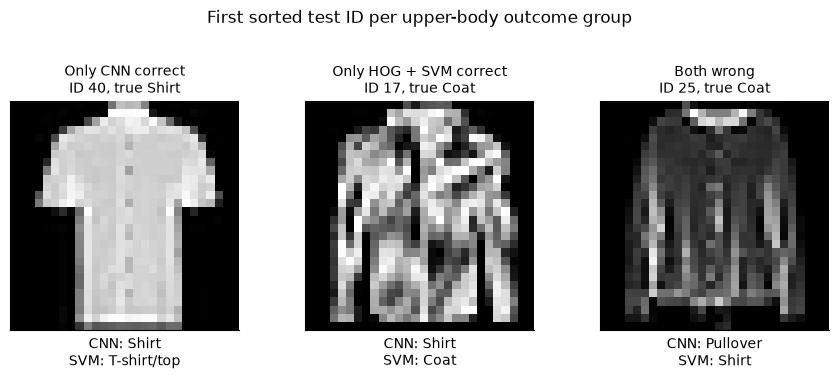

In [11]:
cnn_pred = evidence["predictions"][review.CNN_ID, "test"].sort_values("sample_id")
svm_pred = evidence["predictions"][review.SVM_ID, "test"].sort_values("sample_id")
assert np.array_equal(cnn_pred.sample_id, svm_pred.sample_id)
truth = cnn_pred.y_true.to_numpy()
cnn_ok = cnn_pred.y_pred.to_numpy() == truth
svm_ok = svm_pred.y_pred.to_numpy() == truth
paired = pd.DataFrame({"Outcome": ["Both correct", "Only CNN correct", "Only SVM correct", "Both wrong"],
                       "Count": [(cnn_ok & svm_ok).sum(), (cnn_ok & ~svm_ok).sum(),
                                 (~cnn_ok & svm_ok).sum(), (~cnn_ok & ~svm_ok).sum()]})
assert paired.Count.sum() == 10000
assert int(paired.Count.iloc[1]-paired.Count.iloc[2]) == 123
display(paired)
review.error_plot(evidence)
plt.show()

The CNN corrects 425 images the SVM misses and loses 302 the SVM gets right.
The difference is 123 additional correct labels. For true Shirt, the CNN sends
134 images to T-shirt/top versus the SVM's 103. In the reverse direction, the
CNN sends 64 T-shirts to Shirt versus 104 for SVM. Shirt precision rises while
recall falls. A visible neckline or fastening suggests an explanation to
investigate, with the recorded labels and predictions as direct observations.

### Uncertainty and inference cost

In [12]:
uncertainty = read_json(review.FULL / "evaluation/cnn_vs_svm_deltas.json")
bootstrap = uncertainty["paired_bootstrap"]
display(pd.DataFrame({"Metric": ["Accuracy gain (pp)", "Macro F1 gain"],
                      "Estimate": [100*(cnn.test_accuracy-svm.test_accuracy), cnn.test_macro_f1-svm.test_macro_f1],
                      "95% lower": [100*bootstrap["accuracy_delta_ci95"][0], bootstrap["macro_f1_delta_ci95"][0]],
                      "95% upper": [100*bootstrap["accuracy_delta_ci95"][1], bootstrap["macro_f1_delta_ci95"][1]]}))
timing = evidence["timing"]
display(pd.DataFrame([{"Pipeline": name, **row["batch128_amortized"]}
                      for name,row in timing["measurements"].items()])[
    ["Pipeline", "median_ms_per_image", "min_ms_per_image", "max_ms_per_image", "images", "batch_size", "repeats"]])
print("Recorded CPU/environment:", timing["environment"])

,Metric,Estimate,95% lower,95% upper
0,Accuracy gain (pp),1.2300,0.7300,1.750
1,Macro F1 gain,0.0118,0.0067,0.017


,Pipeline,median_ms_per_image,min_ms_per_image,max_ms_per_image,images,batch_size,repeats
0,hog_svm,19.7483,19.3017,19.9025,1024,128,5
1,selected_cnn,0.3120,0.2934,0.4210,1024,128,5
2,emb_lr,0.3146,0.2941,0.3930,1024,128,5
3,hog_lr,0.2053,0.2037,0.2151,1024,128,5
4,fusion_lr,0.5175,0.5151,0.5537,1024,128,5


Recorded CPU/environment: {'python': '3.12.5', 'platform': 'macOS-26.2-arm64-arm-64bit', 'cpu': 'Apple M3', 'logical_cpus': 8, 'torch': '2.15.0', 'torch_threads': 1, 'torch_interop_threads': 1, 'native_threads': 'threadpoolctl limits=1 for NumPy/BLAS/OpenMP', 'device': 'cpu (no accelerator numbers reported)', 'numpy': '2.5.5', 'scikit-learn': '1.9.1', 'scikit-image': '0.26.0', 'threadpoolctl': '3.8.0', 'joblib': '1.6.0'}


The bootstrap used 2,000 aligned-pair resamples and seed 42. Its accuracy-gain
interval is +0.73 to +1.75 percentage points. This interval covers sampling
variability of the benchmark images. Training-seed variability remains unmeasured.

The recorded CPU timer used 1,024 original test IDs, batches of 128, one warm-up
and five repeats under one PyTorch/native thread. It includes input conversion,
feature extraction and prediction, with loaded models. CNN-3 costs 0.312 ms/image
versus 19.748 for HOG + SVM, about 63.3 times lower on that machine. The SVM used
a recorded deterministic refit that matched all 10,000 original predictions.

## Takeaways

- Learned features improve aggregate metrics under the recorded benchmark protocol.
- Shirt remains difficult. The CNN's precision/recall change shifts the class boundary.
- Embedding-only LR is a strong frozen control. Adding HOG reduces validation F1.
- Dropout, depth and augmentation need measured controls and careful scope.
- One seed, the examined public test set, near-copy findings and one-machine timing
  limit claims about another training run or production catalogue photographs.

### Saved evidence and handoff

`results/phase2/integration/audit.json` records the expanded 31-file audit.
`docs/phase2_integration_nakul.md` links the integration protocol and final artifacts.
`report/phase2/` contains the IEEE/LaTeX sources and compiled report.
The PowerPoint uses short Hinglish presenter notes, matching the team's Phase 1 preference.